# Monte Carlo Markov Chain (MCMC)


A **Markov Chain** is a `random walk` that maintains the **memoryless property**. In other words, each step, or probability, in the system is independent of the previous (only the last one).


In probability theory and statistics, a Markov chain or Markov process is a stochastic process describing a sequence of possible events in which the probability of each event depends only on the state attained in the previous event. Informally, this may be thought of as, "What happens next depends only on the state of affairs now

<img src="https://upload.wikimedia.org/wikipedia/commons/2/2b/Markovkate_01.svg" width="400">

## Random numbers (pseudo random)

Before moving in details, let's consider some kinds of **random numbers generators** and the **random walk**.

In [37]:
import numpy as np
import random
import pandas as pd
import math
import matplotlib.pyplot as plt

In [2]:
#Función randint: genera un número aleatorio entero entre 0 y n.
print('randint =',random.randint(0, 10))

#Función uniform: nos permite generar valores aleatorios que sean decimales podemos hacer uso de uniform.
print('uniform =',random.uniform(0, 10))

#Función random: random que no acepta parámetros y genera números aleatorios decimales de entre 0 y 1.
print('random =',random.random())

#Función choice:nos permite elegir un elemento aleatorio de una lista.
mylist = ['11', '22', '33']
print('choice =',random.choice(mylist))

randint = 4
uniform = 4.9785392882726605
random = 0.7768422949940076
choice = 33


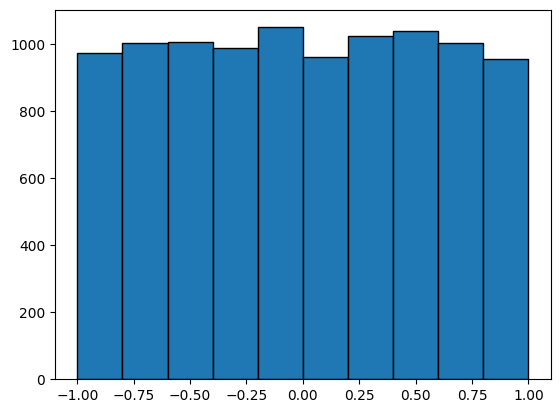

In [37]:
samples = [random.uniform(-1, 1) for _ in range(10000)]

plt.hist(samples, bins=10, edgecolor='black')
plt.show()

### The Drunkard’s Walk ... the random walk

Let's consider a drunk wall where in each step the drunk man maintains the same probability of moving forwards or backwards whether he’s on the cliff’s edge or many steps away from it.

**1D Random Walk**
This example simulates a one-dimensional random walk where a walker starts at a fixed point and moves left or right randomly at each step. The path of the walker is plotted using matplotlib.
https://www.geeksforgeeks.org/python/random-walk-implementation-python/

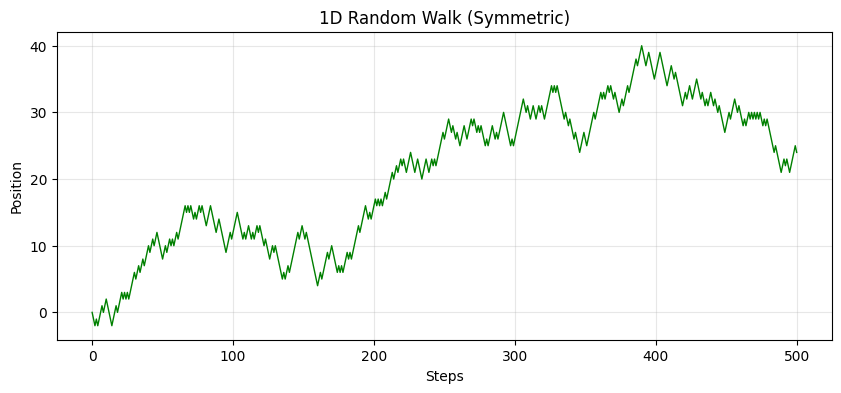

In [3]:
steps = 500
origin = 0

step_set = np.array([-1, 1]) # two posible values
random_steps = np.random.choice(step_set, size=steps) # choice between -1 o +1

path = np.concatenate([[origin], np.cumsum(random_steps)]) # np.cumsum suma las numeros del array sucesivamente

plt.figure(figsize=(10, 4))
plt.plot(path, color='green', linewidth=1)
plt.title("1D Random Walk (Symmetric)")
plt.xlabel("Steps")
plt.ylabel("Position")
plt.grid(True, alpha=0.3)
plt.show()

Explanation:

* origin = 0 walker starts at position 0.
* step_set = np.array([-1, 1]) each step can be -1 (left) or +1 (right).
* np.random.choice(step_set, size=steps) randomly select steps for the walk.
* np.cumsum(random_steps) compute cumulative sum to get walker’s position at each step.

**2D Random Walk in Python**
A 2D random walk lets the walker move in four directions up, down, left or right creating more complex paths compared to 1D. The final path is plotted to visualize the movement on a 2D plane.

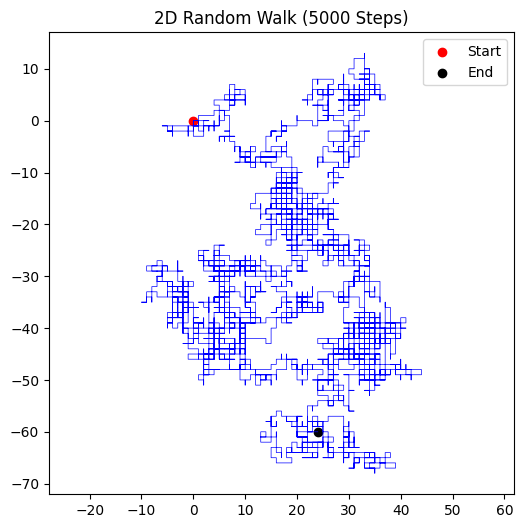

In [5]:
n = 5000
moves = np.array([(0, 1), (0, -1), (1, 0), (-1, 0)])

random_indices = np.random.choice(len(moves), size=n)
steps = moves[random_indices]

coords = np.cumsum(steps, axis=0)
x, y = coords[:, 0], coords[:, 1]

plt.figure(figsize=(6, 6))
plt.plot(x, y, lw=0.5, color='blue')
plt.scatter(0, 0, color='red', label='Start')
plt.scatter(x[-1], y[-1], color='black', label='End')
plt.title(f"2D Random Walk ({n} Steps)")
plt.legend()
plt.axis('equal')
plt.show()

**Explanation:**

* moves = np.array([(0,1),(0,-1),(1,0),(-1,0)]) define possible moves: up, down, right, left.
* np.random.choice(len(moves), size=n) randomly select n moves.
* steps = moves[random_indices] create sequence of steps for the walk.
* np.cumsum(steps, axis=0) compute cumulative (x, y) positions for the walker.
* plt.plot(x, y) plot the 2D path; plt.scatter marks start (red) and end (black).
* plt.axis('equal') ensures x and y axes have the same scale for accurate visualization.

### The Drunkard’s Walk distribution

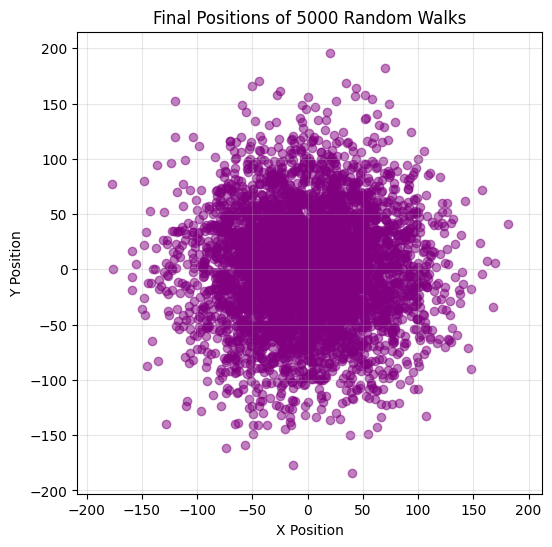

In [6]:
## Mostremos el resultado de 1000 caminatas aleatorias en 2D, cada una con 5000 pasos, 
# para observar la distribución de las posiciones finales.

n_walks = 5000
final_positions = np.zeros((n_walks, 2))
for i in range(n_walks):
    random_indices = np.random.choice(len(moves), size=n)
    steps = moves[random_indices]
    coords = np.cumsum(steps, axis=0)
    final_positions[i] = coords[-1] # Guardamos la posición final de cada caminata
plt.figure(figsize=(6, 6))
plt.scatter(final_positions[:, 0], final_positions[:, 1], alpha=0.5, color='purple')
plt.title(f"Final Positions of {n_walks} Random Walks")
plt.xlabel("X Position")
plt.ylabel("Y Position")
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.show()

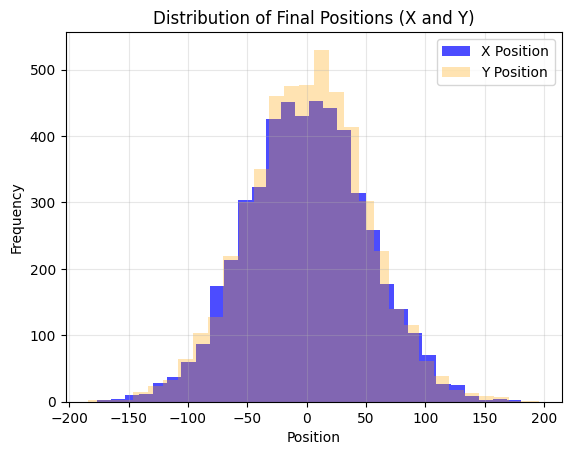

In [7]:
plt.hist(final_positions[:, 0], bins=30, alpha=0.7, color='blue', label='X Position')
plt.hist(final_positions[:, 1], bins=30, alpha=0.3, color='orange', label='Y Position')
plt.title(f"Distribution of Final Positions (X and Y)")
plt.xlabel("Position")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

We see that the distribution is centered in (0,0).

## Statistical distribution

A statistical distribution (or probability distribution) is a mathematical function or model that describes how probabilities or frequencies are distributed among the different possible values ​​of a random variable.

**Discrete and continous distributions**

1. Poisson distribution

$$f(k,\lambda)=\dfrac{\lambda^k e^{-\lambda}}{k!}$$

<img src="https://thumb.wikimedia.org/wikipedia/commons/thumb/1/16/Poisson_pmf.svg/960px-Poisson_pmf.svg.png?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail" width="500">

2. Normal distribution

$$p(x;\mu,\sigma^2)=\dfrac{1}{\sigma \sqrt{2\pi}} e^{-\dfrac{1}{2}\left(\dfrac{x-μ}{\sigma}\right)^2}$$

$\mu$ is the mean. $\sigma$ is the standard deviation. It is for $x$ in $\mathbb{R}$. The values less than one standard deviation from the mean account for $68.27\%$ of the set, while two standard deviations from the mean account for $95.45\%$ and three standard deviations account for $99.73\%$.


<img src="https://thumb.wikimedia.org/wikipedia/commons/thumb/8/8c/Standard_deviation_diagram.svg/1920px-Standard_deviation_diagram.svg.png?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail" width="600">


3. beta distribution

$$f(x;\alpha,\beta)=\dfrac{x^{(\alpha-1)} (1-x)^{\beta-1}}{B(\alpha,\beta)}$$

x in $[0,1]$ with $B(\alpha,\beta)=\dfrac{\Gamma(\alpha)\Gamma(\beta)}{\Gamma(\alpha+\beta)}$.

[see list of probability distributions.](https://en.wikipedia.org/wiki/List_of_probability_distributions)

### PDF in scipy-python

[see documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html)


In [8]:
from scipy.stats import norm
from scipy.stats import beta

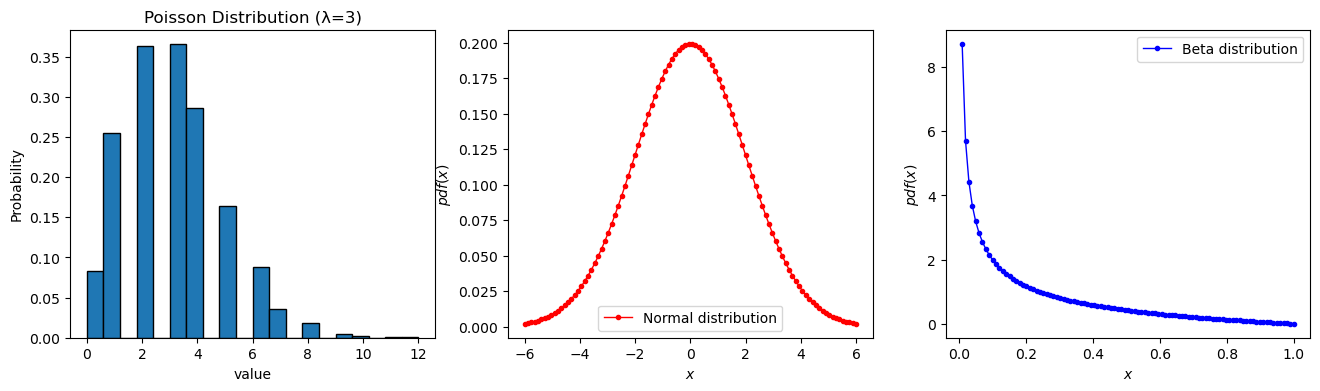

In [7]:
#figure
plt.figure(figsize=(16,4))
#**************** DISCRETE DISTRIBUTIONS
lam=3
data = np.random.poisson(lam=3, size=3000)

plt.subplot(1, 3, 1)
plt.hist(data, bins=20, edgecolor='black', density=True)
plt.title(f"Poisson Distribution (λ={lam})")
plt.xlabel("value")
plt.ylabel("Probability")

#**************** CONTINUOUS DISTRIBUTIONS
x = np.linspace(-6, 6, 100)
x2 = np.linspace(0, 1, 100)
y = norm(0, 2).pdf(x) # mu is 0 y sigma es 2
y2 = beta(0.4, 2).pdf(x2) 

plt.subplot(1, 3, 2)
plt.plot(x, y, 'r.-', lw=1, label='Normal distribution')
plt.xlabel('$x$', fontsize=10)
plt.ylabel('$pdf(x)$', fontsize=10)
plt.legend(fontsize=10)

plt.subplot(1, 3, 3)
plt.plot(x2, y2, 'b.-', lw=1, label='Beta distribution')
plt.xlabel('$x$', fontsize=10)
plt.ylabel('$pdf(x)$', fontsize=10)
plt.legend(fontsize=10)
plt.show()

## Metropolis-Hastings method

* Uno de los MCMC más populares es el algoritmo Metropolis-Hastings; de hecho la mayoría de los algoritmos de MCMC pueden ser interpretados como casos especiales de este algoritmo. 

* El algoritmo Metropolis-Hastings está catalogado como uno de los 10 algoritmos más importantes y más utilizados en ciencia e ingeniería en los últimos años. Se encuentra en el corazón de la mayoría de los métodos de muestreo MCMC. 

* El problema básico que intenta resolver el algoritmo Metropolis-Hastings es proporcionar un método para generar muestras de alguna distribución genérica $P(x)$.

La idea es que en muchos casos, podemos saber cómo escribir la ecuación para la distribución de probabilidad $P(x)$, pero no sabemos cómo generar muestras aleatorias de la misma. Entonces la idea básica detrás de este algoritmo es la de construir una cadena de Markov cuya distribución invariante sea la distribución de muestreo que deseamos, es decir $P(x)$. 

**¿Cómo funciona el Método?**

El algoritmo crea una "cadena", donde cada nuevo estado o muestra depende únicamente del estado anterior. El proceso se repite miles de veces siguiendo estos pasos:

1. *Estado inicial*: Se elige un punto de partida $(x)$ arbitrario para el parámetro que deseas estudiar.
2. *Generar una propuesta*: Se propone un nuevo salto a un estado vecino $(x')$ utilizando una distribución de probabilidad simétrica (por ejemplo, una distribución normal) centrada en el estado actual $(x)$.
3. *Calcular la probabilidad de aceptación $(A)$*: Se compara la probabilidad del nuevo estado propuesto frente a la del estado actual. Esta regla de decisión se calcula matemáticamente así: $$A=\text{min}\left(1,\dfrac{P(x')}{P(x)}\right)$$
4. *Tomar la decisión*:
* Si la probabilidad del nuevo estado es mayor $(P(x') \geq P(x)$, el salto siempre se acepta $A = 1$.
* Si es menor, el salto se puede aceptar o rechazar de forma probabilística. Para ello, el algoritmo genera un número aleatorio entre $[0,1]$ y, si este número es menor que $(A)$, se acepta la propuesta. En caso contrario, se rechaza y te quedas en el estado actual. 
* Iteración: El punto aceptado (o rechazado) se convierte en el nuevo punto de partida y el proceso se repite desde el paso 2.

Tras muchas iteraciones, **el conjunto de puntos aceptados convergerá hacia la distribución de probabilidad real**, permitiendo aproximar comportamientos muy complejos en campos como la física estadística, la inferencia Bayesiana y la computación gráfica

¿cómo funciona? ver:
https://relopezbriega.github.io/blog/2017/01/10/introduccion-a-los-metodos-de-monte-carlo-con-python/

In [28]:
np.random.normal(0, 0.5)

0.40822254047566364

In [29]:
# ****************************************
#     Algorith: Metropolis-Hasting
# ****************************************
def metropolis(func, steps=10000):
    """A very simple Metropolis implementation"""
    muestras = np.zeros(steps)
    old_x = np.random.normal(0, 0.5)  # initial value
    old_prob = func.pdf(old_x)

    for i in range(steps):
        new_x = old_x + np.random.normal(0, 0.5) # to right or left 0.5 maximum
        new_prob = func.pdf(new_x)
        aceptacion = new_prob / old_prob
        if aceptacion >= np.random.random():
            muestras[i] = new_x
            old_x = new_x
            old_prob = new_prob
        else:
            muestras[i] = old_x

    return muestras

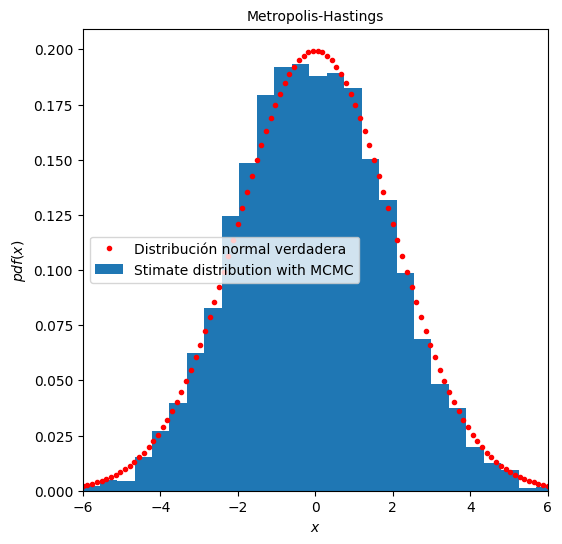

In [30]:
# ******** EXAMPLE 1: FINDINDG A NORMAL DISTRIBUTION ***************

func = norm(0, 2) # Normal distribution
samples = metropolis(func=func) # read the normal distribution
x = np.linspace(-6, 6, 100)
y = func.pdf(x)
plt.figure(figsize=(6,6))
plt.xlim(-6, 6)
plt.plot(x, y, 'r.', lw=3, label='Distribución normal verdadera')
plt.hist(samples, bins=30, density=True, label='Stimate distribution with MCMC')
plt.xlabel('$x$', fontsize=10)
plt.ylabel('$pdf(x)$', fontsize=10)
plt.title('Metropolis-Hastings', fontsize=10)
plt.legend(fontsize=10,loc='best')
plt.show()

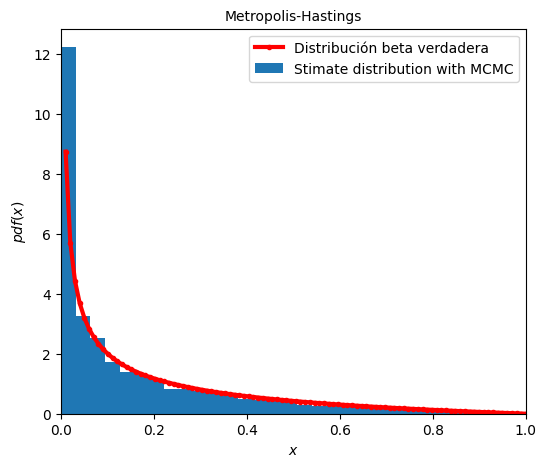

In [31]:
# ******** EXAMPLE 2: FINDINDG A beta DISTRIBUTION ***************

func = beta(0.4, 2)
samples = metropolis(func=func)
x = np.linspace(0, 1, 100)
y = func.pdf(x)

plt.figure(figsize=(6,5))
plt.xlim(0, 1)
plt.plot(x, y, 'r.-', lw=3, label='Distribución beta verdadera')
plt.hist(samples, bins=30, density=True, label='Stimate distribution with MCMC')
plt.xlabel('$x$', fontsize=10)
plt.ylabel('$pdf(x)$', fontsize=10)
plt.title('Metropolis-Hastings', fontsize=10)
plt.legend(fontsize=10,loc='best')
plt.show()

## Modelo de Ising 2D

Como aplicación de la distribución canónica en `Física estadística` tenemos el modelo de **Ising**.
Para el caso de un material paramagnético de átomos de spin $1/2$ y momento magnetico $\mu_0$ en presencia de un campo magnético externo $H$, se ha determinado experimentalmente que la magnetización media depende del campo magnético y la temperatura del material (https://en.wikipedia.org/wiki/Ising_model).

**Ejercicio**: Considere un sistema compuesto por $N$ átomos no interactuantes en un material 2D, a una temperatura $T$ y en presencia de un campo magnético externo $H$ que está orientado en cierta dirección fija respecto al material

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fe/2D_ising_model_on_lattice.svg" width="550">

1. Realizar la simulación mediante el uso del método de **Metrópolis Monte Carlo** para este sistema. Visitar todos los
posibles spines de la red cristalina del material e intentear inversiones bajo condiciones adecuadas de energía y estabilidad del sistema.

    Algoritmo:
    * *Selecciona* un microestado $x$ inicial de manera aleatoria para todos los espines de la red (spin: +1 arriba y -1 abajo). Esta es la configuración inicial.
    * *Visitar* aleatoriamente un punto de la red y hacer una inversión de su espín (configuración $x'$).
    * *Aceptación*: Comprobar la energia $E_i\approx -\vec{\mu}_i\cdot \vec{H}$ del sistema ($\mu_i$ is the Bhor magneton for the electron). 
            Si la energía disminuye se acepta la nueva configuración $x'$. 
            Si aumenta, se debe generar un número aleatorio entre $[0,1]$. Si este número es mayor que el factor de Boltzman $\mathcal{P}(E,T)=e^{-\Delta E/(KT)}$ se rechaza $x'$. De lo contrario se acepta la nueva configuración $x'$.
    * *Repetir* los pasos anteriores.
    * *Finalizar*: Cuando llegue al creterio de finalización.

2. Graficar la **Magnetización media del material vs el campo magnetico** para tres temperaturas reducidas (H/T) con $T=\{5,10,15\}$ K (Kelvin) y un campo variable $-30\,T < H < +30\,T$ (Tesla), .  Monstrar que la distribución canónica de la magnetización clásica es muy acertada (consultar). 
3. Investigar el resultado analítico para este sistema 2D y comparar con la simulación de MC. ¿Qué tan precisa es la simulación? Explique.


### Marco teórico

La propiedad que posee ciertos materiales de magnetizar sus átomos en una misma dirección en
la presencia de un campo magnético externo aplicado es conocida como paramagnetismo. Sin emabrgo,
cuando se presentan temperaturas, sedan casos de aleatoriedad en la
dirección que toman los spines con respecto a este campo modificando las propiedades magnéticas del material.

Consideremos un sistema compuesto de **$N$ átomos no interactuantes** entre sí en una sustancia a
una temperatura $T$ y en presencia de un campo magnético externo $H$ que está orientado en cier­ta dirección (por ejemplo en z).

La energía potencial $E$ de un dipolo magnético (átomo con momento magnético $\vec{\mu}$) inmerso en un campo magnético externo $\vec{H}$ está dada por el producto 

$$E = -\vec{\mu} \cdot \vec{H}$$

Dada la variable de espín $s_i$ se deduce $E_0 = - \mu_0 H s_i$. Al invertir el espín de la particula $i$ se obtiene 
$$\Delta E = - \mu_0 H (-s_i) - (- \mu_0 H s_i) = 2 \mu_0 H s_i$$

Bajo el modelo del **ensamble canónico** tenemos que la magnetización media del material es:

$$\langle M \rangle = N \mu_B \tanh\left(\frac{\mu_B H}{k_B T}\right),$$

donde el **magnetón de Bohr** $\mu_B$ es una constante física que representa la unidad natural del momento magnético de un electrón, ya sea por su movimiento orbital alrededor del núcleo o por su espín.

... la solución clásica propuesta por Langevin es:

$$\langle M \rangle = N \mu_B \left( \coth(x) - \frac{1}{x} \right).$$

**Simulación**

Se realiza una aplicación de distribución canónica para el caso de un material
paramagnético de átomos de spin $1/2$ y momento magnetico $\mu_0$, en presencia de un campo magnético externo.
La magnetización media depende del campo y la temperatura conforme a una función tangente hiperbolica. 
Se realiza esta simulación mediante el uso del método de **Metrópolis Monte Carlo** en el cual se visitan todos los
posibles spines de la red cristalina del material y se intentan inversiones bajo
condiciones de energía. Se comprueba mediante la simulación, que la distribución canónica de la magnetización clásica es muy acertada.

En el proceso de simulación seleccionamos aleotoriamente una configuración, la cual
proporcionara una energía posible para nuestra muestra. Se evaluan los cambios en la
energía, dejándose aquellas que proporcionen valores menores al partir de una semilla dada.
* Si la energía es menor que la del paso anterior, se acepta como una nueva configuración altamente probable. 
* Si la energía es mayor, se genera un número aleatorio. Si este número es mayor que el factor de Bolzman $e^{-\beta E}$ se
rechaza y no contaba en el promedio final. Si el número es menor se acepta como
una posible nueva configuración para nuestro sistema.
Se repite el proceso escogíendo otra configuración aleatoria hasta llegar a la condición de parada.

**Biblografía**

* Federick Reif, Statistical and termal physics; Mc GRAW HILL INTERNATIONAL EDITIONS


In [32]:
#*********** MKS units **************
# Vacuum permeability (H/m)
mu0 = 4*np.pi*1e-7 
# Boltzmann constant (J/K)
k = 1.380649e-23
# Bohr magneton (J/T)
muB = 9.2740100783e-24
# g factor for electron
g = 2.00231930436256

print(f"Ratio of Bohr magneton to Boltzmann constant: {muB/k:.3e}\n")

#*********** CGS units ***************
# 1 T = 10^4 G
# k boltzmann in Gassian units (erg/K)
k_gauss = k*1e7
# c speed of ligth in cm/s
c_gauss = 2.99792458e10
# permeability of free space in Gaussian units (dimensionless)
mu0_gauss = 1/c_gauss**2
# Bohr magneton in Gaussian units (erg/G)           
muB_gauss = muB*1e7/1e4

print(f"Boltzmann constant: {k_gauss:.3e} erg/K")
print(f"Speed of light: {c_gauss:.3e} cm/s")
print(f"Permeability of free space: {mu0_gauss:.3e}")
print(f"Bohr magneton: {muB_gauss:.3e} erg/G")

print(f"Ratio of Bohr magneton to Boltzmann constant: {muB_gauss/k_gauss:.3e} K/G")

Ratio of Bohr magneton to Boltzmann constant: 6.717e-01

Boltzmann constant: 1.381e-16 erg/K
Speed of light: 2.998e+10 cm/s
Permeability of free space: 1.113e-21
Bohr magneton: 9.274e-21 erg/G
Ratio of Bohr magneton to Boltzmann constant: 6.717e-05 K/G


In [35]:
# initializate the red and the energy matrix
n = 10  # size of the red
red = np.random.choice([-1, 1], size=(n, n))
energy = np.zeros((n, n))
#print(red)

In [50]:
x = []

C = 0.6717098224 # magneton de Bhor under k (Kelvin/Tesla)
#******** Temperature ***********************
for T in [5,10,15]: # temperature in K

    # for magnetic field in Teslas (Gauss is not enough for this simulation)
    for H in np.arange(-30, 31, 0.5): 
        Mag = 0 # magnetization

        # ************** int of Monte Carlo *******************
        MC = 100 # number of Monte Carlo steps
        for m in range(MC): 
            # loop over onetime red matrix for Hi:
            for i in range(n):
                for j in range(n):
                    energy[i,j] = -red[i,j]*H
                    stemp = -red[i,j]
                    energytemp = -stemp*H
                    deltae = energytemp - energy[i,j]
                    # Metropolis algorithm
                    if deltae <= 0:
                        red[i,j] = stemp
                    # Metropolis algorithm with Boltzmann factor
                    else:
                        b = np.exp(-deltae*C/T) # In MKS or CGSis the same
                        r = np.random.rand() # random number between 0 and 1
                        if r < b:
                            red[i,j] = stemp   # inverse the spin 
                    # calculate the magnetization in one Monte Carlo step
                    Mag += red[i,j]
            #print("Magnetization:", Mag)                

        Magpro = Mag/MC # normalize the magnetization
        # print(energy)
        # print(red)
        #print("Magnetization per spin:", Magpro)
        # ************** end of Monte Carlo *******************
        x.append([T,H, Magpro])
#******** for temperature *****************

x=np.asarray(x)
xd=pd.DataFrame(x,columns=['T','H','Magnetization'])

# dataframe for each temperature
T1 = xd[xd['T'] == 5]
T2 = xd[xd['T'] == 10]
T3 = xd[xd['T'] == 15]

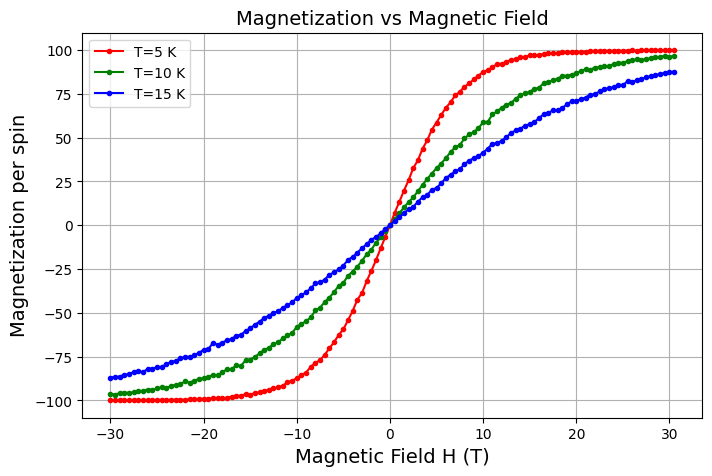

In [51]:
plt.figure(figsize=(8,5))
plt.plot(T1['H'], T1['Magnetization'],'r.-',label='T=5 K')
plt.plot(T2['H'], T2['Magnetization'],'g.-',label='T=10 K')
plt.plot(T3['H'], T3['Magnetization'],'b.-',label='T=15 K')
plt.xlabel('Magnetic Field H (T)',size=14)
plt.ylabel('Magnetization per spin',size=14)
plt.title('Magnetization vs Magnetic Field',size=14)
plt.legend(loc='best')
plt.grid()
plt.show()

Analytical comparation

$$\langle M \rangle = N \mu_B \tanh\left(\frac{\mu_B H}{k_B T}\right)$$

In [52]:
# Magnetization of a paramagnetic material in the presence of an external magnetic field H at temperature T.
def Magnetization(N,H,T):
    '''Calculate the magnetization of a paramagnetic material. Units Joule/Tesla. 
    N is the number of magnetic moments, 
    H is the external magnetic field in Gauss, 
    T is the temperature in Kelvin.'''
    muB = 9.2740100783e-24 # Bohr magneton (J/T)
    k = 1.380649e-23       # Boltzmann constant (J/K)
    
    return N*muB*np.tanh(muB*H/(k*T))

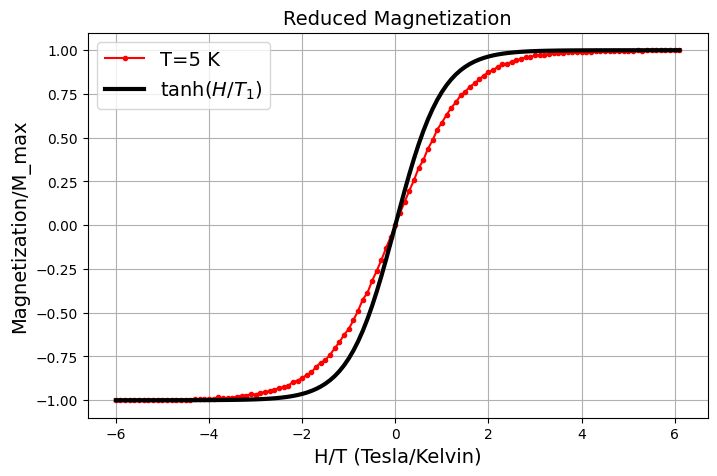

In [53]:
plt.figure(figsize=(8,5))
plt.plot(T1['H']/T1['T'].max(), T1['Magnetization']/T1['Magnetization'].max(),'r.-',label='T=5 K')
#plt.plot(T2['H']/T2['T'].max(), T2['Magnetization']/T2['Magnetization'].max(),'g.-',label='T=10 K')
#plt.plot(T3['H']/T3['T'].max(), T3['Magnetization']/T3['Magnetization'].max(),'b-',label='T=15 K')

plt.plot(T1['H']/5, np.tanh(T1['H']/5),'k-',lw=3,label='$\\tanh (H/T_1)$')

plt.xlabel('H/T (Tesla/Kelvin)', size=14)
plt.ylabel('Magnetization/M_max', size=14)
plt.title('Reduced Magnetization', size=14)
plt.legend(fontsize=14, loc='best')
plt.grid()
plt.show()